# TrustJob AI — Détection des offres d’emploi frauduleuses

Objectif : analyser le texte et les attributs d’une annonce, puis estimer si elle ressemble aux annonces frauduleuses du jeu d’entraînement.

La cible fraudulent vaut 0 (non signalée comme frauduleuse) ou 1 (signalée comme frauduleuse). Le modèle donne une estimation statistique, pas une preuve juridique.

Ce notebook comprend l’exploration, le nettoyage, un repère traditionnel à règles, quatre modèles de machine learning, une validation croisée à quatre plis, l’évaluation, la sauvegarde du pipeline et la génération du fichier de prédictions.

## Installation et données

Bibliothèques requises : pandas, numpy, matplotlib, seaborn, scikit-learn, joblib et streamlit. Elles doivent être installées dans le même environnement que le kernel du notebook.

Les CSV sont recherchés dans C:/Users/MSI/Desktop/PROJET, puis dans le dossier courant. Modifiez DATA_DIR dans la cellule suivante si les fichiers sont ailleurs.

Le PDF de cadrage mentionne environ 17 880 annonces pour certaines versions d’EMSCAD. Les CSV fournis ici contiennent 12 000 lignes d’entraînement et 18 colonnes ; le notebook affiche les dimensions réellement lues.

In [1]:
from pathlib import Path
import json
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.feature_selection import SelectKBest, chi2
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import LinearSVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split, GridSearchCV, StratifiedKFold
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, confusion_matrix, classification_report,
                             ConfusionMatrixDisplay)

SEED = 42
TARGET = "fraudulent"
DATA_DIR = Path(r"C:/Users/MSI/Desktop/PROJET")
if not (DATA_DIR / "job_postings_train.csv").exists():
    DATA_DIR = Path.cwd()
OUTPUT_DIR = Path.cwd() / "outputs"
OUTPUT_DIR.mkdir(exist_ok=True)

TEXT_FIELDS = [
    "title", "location", "department", "salary_range", "company_profile",
    "description", "requirements", "benefits", "employment_type",
    "required_experience", "required_education", "industry", "function"
]
FLAG_FIELDS = ["telecommuting", "has_company_logo", "has_questions"]
print("Dossier données :", DATA_DIR.resolve())
print("Dossier résultats :", OUTPUT_DIR.resolve())

Dossier données : C:\Users\MSI\Desktop\PROJET
Dossier résultats : C:\Users\MSI\.codex\.chatgpt-projects\g-p-6aff68e98a4c8191997b67c8226fa257\outputs


In [2]:
train = pd.read_csv(DATA_DIR / "job_postings_train.csv")
test = pd.read_csv(DATA_DIR / "job_postings_test.csv")
sample_submission = pd.read_csv(DATA_DIR / "job_postings_sample_submission.csv")

print("Dimensions train :", train.shape)
print("Dimensions test sans étiquettes :", test.shape)
print("Colonnes :", train.columns.tolist())
assert TARGET in train.columns, f"La cible {TARGET!r} est absente."
assert set(TEXT_FIELDS + FLAG_FIELDS).issubset(train.columns), "Une colonne attendue manque."
display(train.head())
train.info()
display(train.describe(include='all').T)
for col in ['employment_type', 'required_experience', 'required_education', 'industry', 'function']:
    print(col, ':', train[col].nunique(dropna=True), 'valeurs non vides')
    display(train[col].fillna('Non renseigné').value_counts().head(8).rename('effectif').to_frame())

Dimensions train : (12000, 18)
Dimensions test sans étiquettes : (5599, 17)
Colonnes : ['id', 'title', 'location', 'department', 'salary_range', 'company_profile', 'description', 'requirements', 'benefits', 'telecommuting', 'has_company_logo', 'has_questions', 'employment_type', 'required_experience', 'required_education', 'industry', 'function', 'fraudulent']


,id,title,location,department,salary_range,company_profile,description,requirements,benefits,telecommuting,has_company_logo,has_questions,employment_type,required_experience,required_education,industry,function,fraudulent
0,14845,Cluster Computing Apprentice,"US, OR, Portland",Engineering,50000-90000,Urban Robotics Inc. provides cutting edge soft...,Company OverviewUrban Robotics Inc. (UR) is an...,Non-NegotiablesWe strive to hire top quality c...,Compensation is based on experience and educat...,0,1,1,Full-time,Mid-Senior level,Bachelor's Degree,Computer Software,Engineering,0
1,1948,Structured Finance Associate,"US, NC, 28202",Legal,NaN,NaN,Special Counsel’s Charlotte office has an exci...,NaN,NaN,0,1,0,NaN,NaN,NaN,NaN,NaN,0
2,11235,Software and Security Engineering / Open Posit...,"GB, , London",Engineering,NaN,Medopad is the leading enterprise mobile healt...,Medopad is the leading enterprise mobile healt...,NaN,NaN,0,1,1,Full-time,Entry level,NaN,NaN,Engineering,0
3,16320,Corporate Sales Manager,"US, CA, Santa Clara",Sales,NaN,"Palerra, Inc. designed LORIC™ to protect an en...",Generate new business opportunities to drive t...,NaN,NaN,0,1,0,Full-time,Mid-Senior level,NaN,Computer Software,Sales,0
4,11671,Customer Service Representatives,"US, NY, Farmingdale",NaN,NaN,"For over 20 years NAC Marketing Company, LLC d...",• Answer both incoming customer service calls ...,• 6 months work experience • High school diplo...,"We believe in the philosophy ‘be healthy, live...",0,1,0,Full-time,Entry level,NaN,NaN,Customer Service,0


<class 'pandas.DataFrame'>
RangeIndex: 12000 entries, 0 to 11999
Data columns (total 18 columns):
 #   Column               Non-Null Count  Dtype
---  ------               --------------  -----
 0   id                   12000 non-null  int64
 1   title                12000 non-null  str  
 2   location             11773 non-null  str  
 3   department           4324 non-null   str  
 4   salary_range         1963 non-null   str  
 5   company_profile      9785 non-null   str  
 6   description          11999 non-null  str  
 7   requirements         10204 non-null  str  
 8   benefits             7186 non-null   str  
 9   telecommuting        12000 non-null  int64
 10  has_company_logo     12000 non-null  int64
 11  has_questions        12000 non-null  int64
 12  employment_type      9648 non-null   str  
 13  required_experience  7242 non-null   str  
 14  required_education   6523 non-null   str  
 15  industry             8689 non-null   str  
 16  function             7705 non-nul

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
id,12000.0,NaN,NaN,NaN,8944.441333,5184.320075,1.0,4457.75,8894.0,13460.75,17879.0
title,12000,8101,English Teacher Abroad,200,NaN,NaN,NaN,NaN,NaN,NaN,NaN
location,11773,2517,"GB, LND, London",515,NaN,NaN,NaN,NaN,NaN,NaN,NaN
department,4324,1042,Sales,386,NaN,NaN,NaN,NaN,NaN,NaN,NaN
salary_range,1963,706,0-0,101,NaN,NaN,NaN,NaN,NaN,NaN,NaN
company_profile,9785,1508,We help teachers get safe &amp; secure jobs ab...,473,NaN,NaN,NaN,NaN,NaN,NaN,NaN
description,11999,10364,"Play with kids, get paid for it Love travel? J...",253,NaN,NaN,NaN,NaN,NaN,NaN,NaN
requirements,10204,8407,University degree required. TEFL / TESOL / CEL...,264,NaN,NaN,NaN,NaN,NaN,NaN,NaN
benefits,7186,4543,See job description,473,NaN,NaN,NaN,NaN,NaN,NaN,NaN
telecommuting,12000.0,NaN,NaN,NaN,0.043833,0.204733,0.0,0.0,0.0,0.0,1.0


employment_type : 5 valeurs non vides


,effectif
employment_type,
Full-time,7801
Non renseigné,2352
Contract,1007
Part-time,525
Temporary,171
Other,144


... (4 outputs left out)

industry : 128 valeurs non vides


,effectif
industry,
Non renseigné,3311
Information Technology and Services,1165
Computer Software,953
Internet,720
Education Management,533
Marketing and Advertising,531
Financial Services,520
Hospital & Health Care,331


function : 37 valeurs non vides


,effectif
function,
Non renseigné,4295
Information Technology,1198
Sales,985
Engineering,930
Customer Service,825
Marketing,558
Administrative,414
Health Care Provider,226


## 1 — Vérification, doublons et données manquantes

L’identifiant id ne sera pas utilisé comme prédicteur. Les doublons exacts hors identifiant sont comptés, puis retirés. Les valeurs textuelles manquantes seront remplacées par des chaînes vides et les indicateurs binaires manquants par 0 dans la préparation.

In [3]:
feature_columns_for_duplicates = [c for c in train.columns if c != "id"]
duplicate_count = int(train.duplicated(subset=feature_columns_for_duplicates).sum())
print("Doublons exacts hors identifiant :", duplicate_count)
train = train.drop_duplicates(subset=feature_columns_for_duplicates).copy()

missing = train.isna().sum().sort_values(ascending=False)
display(missing[missing > 0].rename("valeurs manquantes").to_frame())
y = train[TARGET].astype(int)
class_counts = y.value_counts().sort_index()
print("Effectifs :")
print(class_counts.rename(index={0: "Légitimes", 1: "Frauduleuses"}))
print(f"Taux frauduleux : {y.mean():.2%}")
print(f"Accuracy si l’on prédit toujours légitime : {(y == 0).mean():.2%} (aucune fraude détectée).")

Doublons exacts hors identifiant : 0


,valeurs manquantes
salary_range,10037
department,7676
required_education,5477
benefits,4814
required_experience,4758
function,4295
industry,3311
employment_type,2352
company_profile,2215
requirements,1796


Effectifs :
fraudulent
Légitimes       11411
Frauduleuses      589
Name: count, dtype: int64
Taux frauduleux : 4.91%
Accuracy si l’on prédit toujours légitime : 95.09% (aucune fraude détectée).


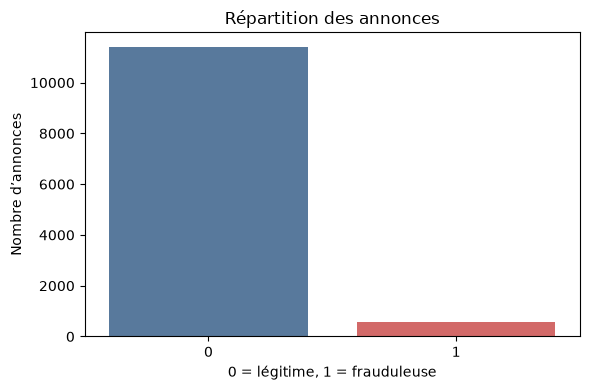

Interprétation : la classe frauduleuse est minoritaire ; l’accuracy seule ne suffit pas.


In [4]:
fig, ax = plt.subplots(figsize=(6, 4))
sns.countplot(data=train, x=TARGET, hue=TARGET, legend=False, palette=["#4C78A8", "#E45756"], ax=ax)
ax.set(title="Répartition des annonces", xlabel="0 = légitime, 1 = frauduleuse", ylabel="Nombre d’annonces")
plt.tight_layout()
plt.show()
print("Interprétation : la classe frauduleuse est minoritaire ; l’accuracy seule ne suffit pas.")

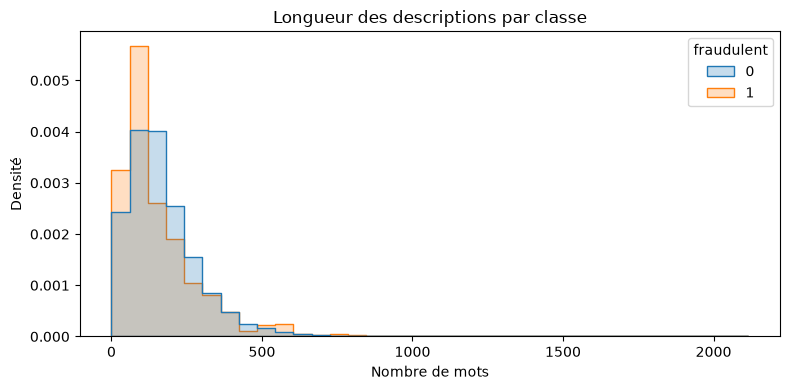

Interprétation : ce graphique compare les distributions ; il ne démontre pas un lien causal.


In [5]:
eda = train[[TARGET, "description"]].copy()
eda["longueur_mots"] = eda["description"].fillna("").astype(str).str.split().str.len()
fig, ax = plt.subplots(figsize=(8, 4))
sns.histplot(data=eda, x="longueur_mots", hue=TARGET, bins=35, stat="density",
             common_norm=False, element="step", ax=ax)
ax.set(title="Longueur des descriptions par classe", xlabel="Nombre de mots", ylabel="Densité")
plt.tight_layout()
plt.show()
print("Interprétation : ce graphique compare les distributions ; il ne démontre pas un lien causal.")

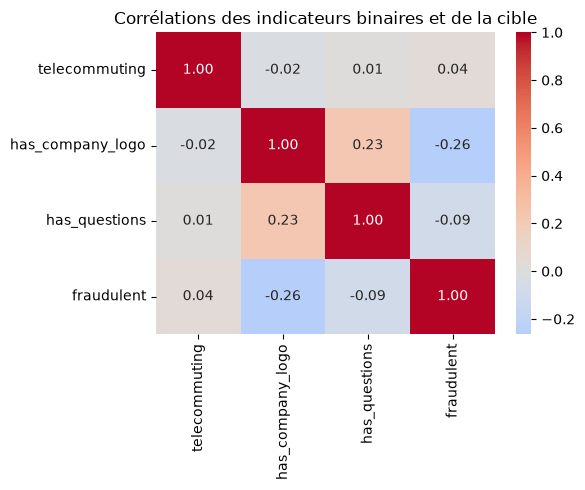

Interprétation : les corrélations sont descriptives et ne démontrent pas de causalité.


In [6]:
numeric_for_corr = train[FLAG_FIELDS + [TARGET]].apply(pd.to_numeric, errors="coerce")
fig, ax = plt.subplots(figsize=(6, 5))
sns.heatmap(numeric_for_corr.corr(), annot=True, cmap="coolwarm", center=0, fmt=".2f", ax=ax)
ax.set_title("Corrélations des indicateurs binaires et de la cible")
plt.tight_layout()
plt.show()
print("Interprétation : les corrélations sont descriptives et ne démontrent pas de causalité.")

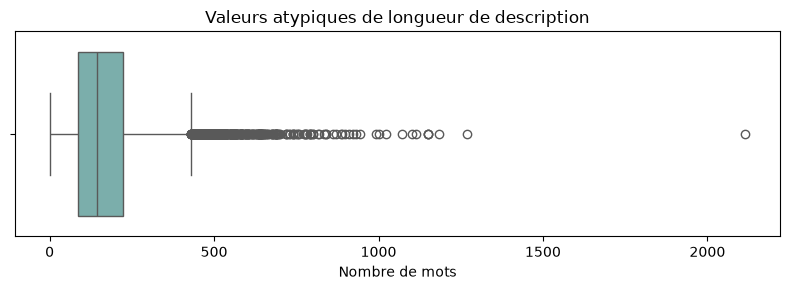

IQR : Q1=87, Q3=224, borne supérieure=430; annonces au-dessus=440.
Décision : les annonces longues sont conservées, car leur longueur n’est pas nécessairement une erreur.


In [7]:
q1, q3 = eda["longueur_mots"].quantile([0.25, 0.75])
iqr = q3 - q1
borne_sup = q3 + 1.5 * iqr
nb_atypiques = int((eda["longueur_mots"] > borne_sup).sum())
fig, ax = plt.subplots(figsize=(8, 3))
sns.boxplot(x=eda["longueur_mots"], color="#72B7B2", ax=ax)
ax.set(title="Valeurs atypiques de longueur de description", xlabel="Nombre de mots")
plt.tight_layout()
plt.show()
print(f"IQR : Q1={q1:.0f}, Q3={q3:.0f}, borne supérieure={borne_sup:.0f}; annonces au-dessus={nb_atypiques}.")
print("Décision : les annonces longues sont conservées, car leur longueur n’est pas nécessairement une erreur.")

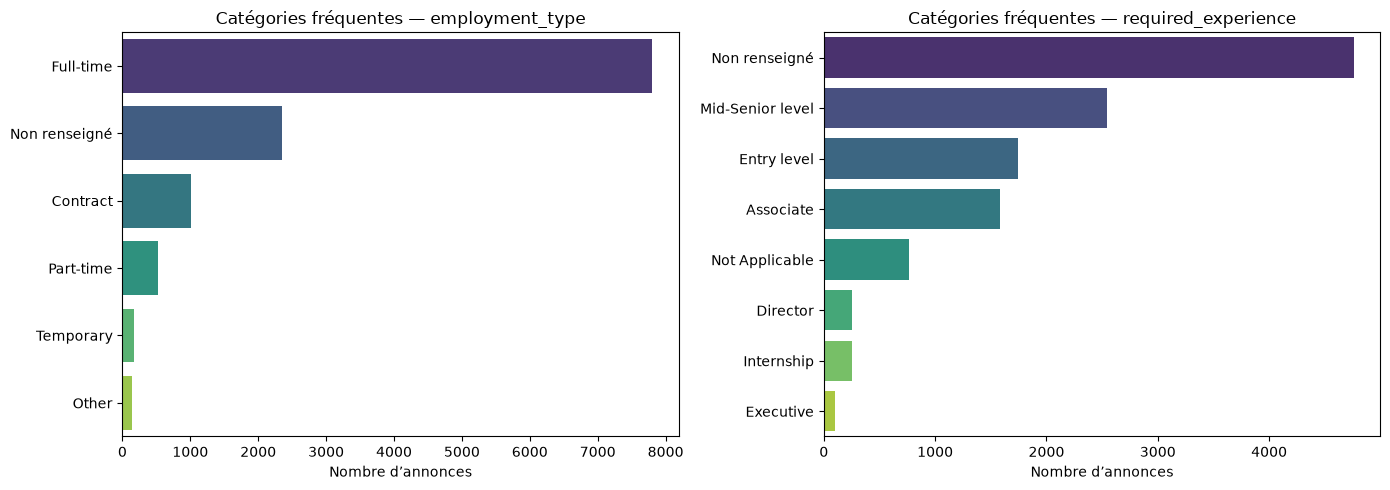

Interprétation : les dix catégories les plus fréquentes sont affichées ; les champs vides sont imputés dans la préparation.


In [8]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for col, ax in zip(["employment_type", "required_experience"], axes):
    counts = train[col].fillna("Non renseigné").value_counts().head(10)
    sns.barplot(x=counts.values, y=counts.index, hue=counts.index, legend=False, palette="viridis", ax=ax)
    ax.set(title=f"Catégories fréquentes — {col}", xlabel="Nombre d’annonces", ylabel="")
plt.tight_layout()
plt.show()
print("Interprétation : les dix catégories les plus fréquentes sont affichées ; les champs vides sont imputés dans la préparation.")

## 2 — Prétraitement et sélection sans fuite

Les textes sont concaténés puis transformés en TF-IDF (unigrammes et bigrammes). SelectKBest avec chi² réduit la dimension. Les trois indicateurs binaires sont conservés. Les champs catégoriels textuels sont inclus dans le texte concaténé.

Toutes les transformations sont intégrées au Pipeline : elles sont réapprises dans chaque pli de validation et ajustées uniquement sur l’apprentissage. La matrice TF-IDF est creuse ; le scaling est omis, car il n’est pas adapté à cette représentation sparse.

In [9]:
def prepare(frame):
    out = pd.DataFrame(index=frame.index)
    out["text"] = frame[TEXT_FIELDS].fillna("").astype(str).agg(" ".join, axis=1)
    for col in FLAG_FIELDS:
        out[col] = pd.to_numeric(frame[col], errors="coerce").fillna(0).astype(float)
    return out

X = prepare(train)
y = train[TARGET].astype(int)
X_train, X_holdout, y_train, y_holdout = train_test_split(
    X, y, test_size=0.20, random_state=SEED, stratify=y
)
print("Apprentissage :", X_train.shape, "| test interne :", X_holdout.shape)
print("Taux fraude train :", f"{y_train.mean():.2%}")
print("Taux fraude test interne :", f"{y_holdout.mean():.2%}")

def make_pipeline(estimator):
    text_pipeline = Pipeline([
        ("tfidf", TfidfVectorizer(
            stop_words="english", ngram_range=(1, 2), min_df=2,
            max_features=20000, sublinear_tf=True
        )),
        ("select", SelectKBest(score_func=chi2, k=3000)),
    ])
    features = ColumnTransformer([
        ("text", text_pipeline, "text"),
        ("flags", "passthrough", FLAG_FIELDS),
    ], sparse_threshold=1.0)
    return Pipeline([("features", features), ("model", estimator)])

Apprentissage : (9600, 4) | test interne : (2400, 4)
Taux fraude train : 4.91%
Taux fraude test interne : 4.92%


## 3 — Méthode traditionnelle de comparaison

Une règle lexicale fixe signale une annonce si le texte contient des expressions telles que « frais de dossier », « upfront fee » ou « bank account ». Elle n’apprend pas à partir des données et sert seulement de repère ; elle peut rater une fraude ou signaler une annonce légitime.

In [10]:
RULE_TERMS = [
    "upfront fee", "processing fee", "application fee", "pay a fee",
    "wire transfer", "western union", "money order", "bank account",
    "social security number", "passport", "frais de dossier",
    "paiement préalable", "virement bancaire", "coordonnées bancaires"
]
def traditional_rule(text):
    text = str(text).lower()
    return int(any(term in text for term in RULE_TERMS))

traditional_text = train.loc[X_holdout.index, TEXT_FIELDS].fillna("").astype(str).agg(" ".join, axis=1)
traditional_pred = traditional_text.map(traditional_rule).to_numpy()
traditional_metrics = {
    "Modèle": "Règle traditionnelle",
    "Meilleurs paramètres": "Liste fixe de mots-clés",
    "F1 CV (4 plis)": np.nan,
    "Accuracy": accuracy_score(y_holdout, traditional_pred),
    "Précision": precision_score(y_holdout, traditional_pred, zero_division=0),
    "Rappel": recall_score(y_holdout, traditional_pred, zero_division=0),
    "F1 test interne": f1_score(y_holdout, traditional_pred, zero_division=0),
}
display(pd.DataFrame([traditional_metrics]))
print(classification_report(y_holdout, traditional_pred, target_names=["Légitime", "Frauduleuse"], zero_division=0))

,Modèle,Meilleurs paramètres,F1 CV (4 plis),Accuracy,Précision,Rappel,F1 test interne
0,Règle traditionnelle,Liste fixe de mots-clés,NaN,0.899167,0.007937,0.008475,0.008197


              precision    recall  f1-score   support

    Légitime       0.95      0.95      0.95      2282
 Frauduleuse       0.01      0.01      0.01       118

    accuracy                           0.90      2400
   macro avg       0.48      0.48      0.48      2400
weighted avg       0.90      0.90      0.90      2400



## 4 — Quatre modèles et validation croisée

Les modèles sont la régression logistique, KNN, le SVM linéaire et Random Forest. GridSearchCV utilise une validation croisée stratifiée à quatre plis et le F1 de la classe frauduleuse comme critère. Les grilles restent compactes pour limiter le temps de calcul du pipeline texte.

In [11]:
cv = StratifiedKFold(n_splits=4, shuffle=True, random_state=SEED)
model_specs = [
    ("Régression logistique", LogisticRegression(
        max_iter=2000, class_weight="balanced", solver="liblinear"
    ), {"model__C": [0.5, 2.0]}),
    ("KNN", KNeighborsClassifier(algorithm="brute"), {
        "model__n_neighbors": [3, 5], "model__weights": ["uniform", "distance"]
    }),
    ("SVM linéaire", LinearSVC(
        class_weight="balanced", random_state=SEED
    ), {"model__C": [0.5, 2.0]}),
    ("Random Forest", RandomForestClassifier(
        n_estimators=50, class_weight="balanced", random_state=SEED, n_jobs=1
    ), {"model__max_depth": [20, None]}),
]
searches = {}
rows = []
for model_name, estimator, param_grid in model_specs:
    print(f"Optimisation : {model_name}")
    search = GridSearchCV(
        estimator=make_pipeline(estimator), param_grid=param_grid,
        scoring="f1", cv=cv, n_jobs=1, refit=True, verbose=1
    )
    search.fit(X_train, y_train)
    pred = search.predict(X_holdout)
    rows.append({
        "Modèle": model_name,
        "Meilleurs paramètres": search.best_params_,
        "F1 CV (4 plis)": search.best_score_,
        "Accuracy": accuracy_score(y_holdout, pred),
        "Précision": precision_score(y_holdout, pred, zero_division=0),
        "Rappel": recall_score(y_holdout, pred, zero_division=0),
        "F1 test interne": f1_score(y_holdout, pred, zero_division=0),
        "Matrice": confusion_matrix(y_holdout, pred, labels=[0, 1]),
    })
    searches[model_name] = search
    print("Meilleurs paramètres :", search.best_params_)
    print(classification_report(y_holdout, pred, target_names=["Légitime", "Frauduleuse"], zero_division=0))

Optimisation : Régression logistique
Fitting 4 folds for each of 2 candidates, totalling 8 fits
Meilleurs paramètres : {'model__C': 2.0}
              precision    recall  f1-score   support

    Légitime       0.99      0.96      0.98      2282
 Frauduleuse       0.55      0.87      0.68       118

    accuracy                           0.96      2400
   macro avg       0.77      0.92      0.83      2400
weighted avg       0.97      0.96      0.96      2400

Optimisation : KNN
Fitting 4 folds for each of 4 candidates, totalling 16 fits
Meilleurs paramètres : {'model__n_neighbors': 3, 'model__weights': 'distance'}
              precision    recall  f1-score   support

    Légitime       0.98      1.00      0.99      2282
 Frauduleuse       0.99      0.63      0.77       118

    accuracy                           0.98      2400
   macro avg       0.98      0.81      0.88      2400
weighted avg       0.98      0.98      0.98      2400

Optimisation : SVM linéaire
Fitting 4 folds for eac

In [12]:
ml_rows = [{k: v for k, v in row.items() if k != "Matrice"} for row in rows]
comparison = pd.DataFrame([traditional_metrics] + ml_rows)
display(comparison.sort_values("F1 test interne", ascending=False).reset_index(drop=True))

,Modèle,Meilleurs paramètres,F1 CV (4 plis),Accuracy,Précision,Rappel,F1 test interne
0,SVM linéaire,{'model__C': 2.0},0.828759,0.984167,0.844828,0.830508,0.837607
1,Random Forest,{'model__max_depth': None},0.754076,0.983750,0.924731,0.728814,0.815166
2,KNN,"{'model__n_neighbors': 3, 'model__weights': 'd...",0.713209,0.981250,0.986667,0.627119,0.766839
3,Régression logistique,{'model__C': 2.0},0.667547,0.959167,0.553763,0.872881,0.677632
4,Règle traditionnelle,Liste fixe de mots-clés,NaN,0.899167,0.007937,0.008475,0.008197


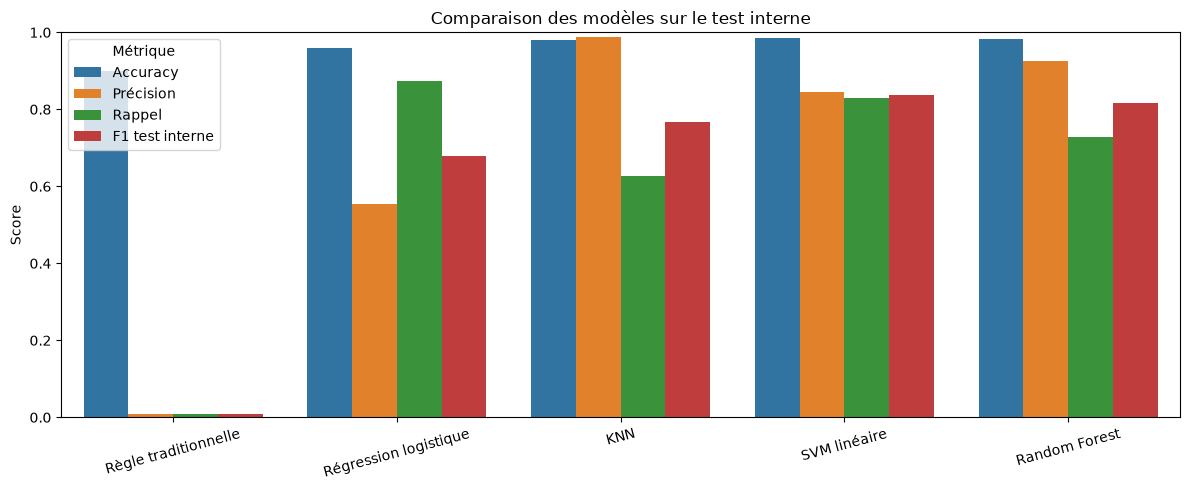

Interprétation : regarder particulièrement le rappel et le F1 ; l’accuracy seule peut cacher des fraudes manquées.


In [13]:
metric_columns = ["Accuracy", "Précision", "Rappel", "F1 test interne"]
plot_data = comparison.melt(
    id_vars="Modèle", value_vars=metric_columns,
    var_name="Métrique", value_name="Score"
)
fig, ax = plt.subplots(figsize=(12, 5))
sns.barplot(data=plot_data, x="Modèle", y="Score", hue="Métrique", ax=ax)
ax.set(title="Comparaison des modèles sur le test interne", ylim=(0, 1), xlabel="", ylabel="Score")
ax.tick_params(axis="x", rotation=15)
plt.tight_layout()
plt.show()
print("Interprétation : regarder particulièrement le rappel et le F1 ; l’accuracy seule peut cacher des fraudes manquées.")

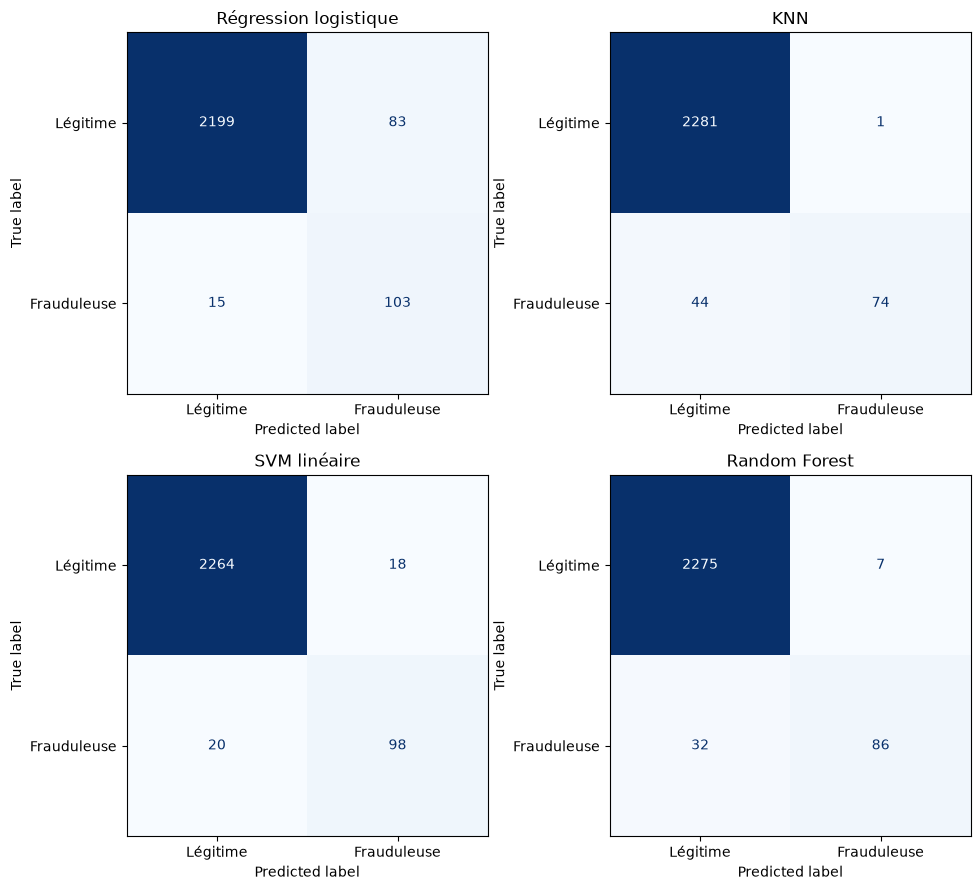

In [14]:
fig, axes = plt.subplots(2, 2, figsize=(10, 9))
for ax, row in zip(axes.ravel(), rows):
    ConfusionMatrixDisplay(
        row["Matrice"], display_labels=["Légitime", "Frauduleuse"]
    ).plot(ax=ax, cmap="Blues", values_format="d", colorbar=False)
    ax.set_title(row["Modèle"])
plt.tight_layout()
plt.show()

In [15]:
best_row = max(rows, key=lambda row: row["F1 test interne"])
best_name = best_row["Modèle"]
print(f"Meilleur modèle selon le F1 interne : {best_name}")
print(f"F1={best_row['F1 test interne']:.3f} | précision={best_row['Précision']:.3f} | rappel={best_row['Rappel']:.3f}")
print("Faux négatif : fraude manquée. Faux positif : annonce légitime signalée à tort.")

Meilleur modèle selon le F1 interne : SVM linéaire
F1=0.838 | précision=0.845 | rappel=0.831
Faux négatif : fraude manquée. Faux positif : annonce légitime signalée à tort.


## 5 — Sauvegarde du modèle complet

Le meilleur modèle est réentraîné sur toutes les annonces étiquetées. Le fichier Joblib inclut le pipeline de traitement texte, la sélection des variables, les indicateurs et le classifieur.

In [16]:
best_pipeline = clone(searches[best_name].best_estimator_)
best_pipeline.fit(X, y)
MODEL_PATH = OUTPUT_DIR / "trustjob_pipeline.joblib"
joblib.dump(best_pipeline, MODEL_PATH, compress=3)
comparison.to_csv(OUTPUT_DIR / "comparaison_modeles_trustjob.csv", index=False)
metrics_json = [
    {k: (float(v) if isinstance(v, (np.floating, np.integer)) else v)
     for k, v in row.items() if k != "Matrice"}
    for row in rows
]
(OUTPUT_DIR / "resultats_trustjob.json").write_text(
    json.dumps({"seed": SEED, "train_shape": list(train.shape),
                "holdout_rows": len(X_holdout), "best_model": best_name,
                "results": metrics_json}, ensure_ascii=False, indent=2),
    encoding="utf-8"
)
print("Pipeline complet sauvegardé :", MODEL_PATH.resolve())

Pipeline complet sauvegardé : C:\Users\MSI\.codex\.chatgpt-projects\g-p-6aff68e98a4c8191997b67c8226fa257\outputs\trustjob_pipeline.joblib


## 6 — Prédictions du fichier test sans étiquettes

Le CSV test n’a pas de cible connue : il ne permet pas de calculer de métriques. Il sert seulement à générer des prédictions au format du fichier de soumission fourni.

In [17]:
test_X = prepare(test)
test_predictions = best_pipeline.predict(test_X).astype(int)
submission = pd.DataFrame({"id": test["id"].values, TARGET: test_predictions})
if list(sample_submission.columns) == list(submission.columns):
    submission = submission[sample_submission.columns]
submission_path = OUTPUT_DIR / "submission_predictions.csv"
submission.to_csv(submission_path, index=False)
print("Prédictions créées :", submission_path.resolve(), "| lignes :", len(submission))
display(submission.head())

Prédictions créées : C:\Users\MSI\.codex\.chatgpt-projects\g-p-6aff68e98a4c8191997b67c8226fa257\outputs\submission_predictions.csv | lignes : 5599


,id,fraudulent
0,8434,0
1,15995,0
2,13508,0
3,12564,0
4,12278,0


## 7 — Interface graphique Streamlit

L’application est dans le fichier app_trustjob_streamlit.py. Après avoir exécuté le notebook jusqu’à la sauvegarde du modèle, ouvrez un terminal dans le dossier du projet et lancez :

~~~text
python -m pip install streamlit
streamlit run app_trustjob_streamlit.py
~~~

L’application demande les champs d’une annonce et affiche une classe ainsi que des indicateurs lexicaux simples. Elle ne donne pas de probabilité, car le modèle retenu n’a pas été calibré. Les mots-clés sont des repères indépendants du modèle, pas des preuves.

## 8 — Clustering exploratoire facultatif (K-Means et CAH)

Le clustering regroupe des annonces semblables sans utiliser la cible. Il ne prédit donc pas directement si une annonce est frauduleuse. Pour limiter le temps de calcul, on utilise un échantillon et une réduction TF-IDF par SVD. La cible est ajoutée ensuite uniquement pour interpréter les groupes.

,annonces,taux_fraude
groupe_kmeans,,
0,769,0.055917
1,31,0.000000


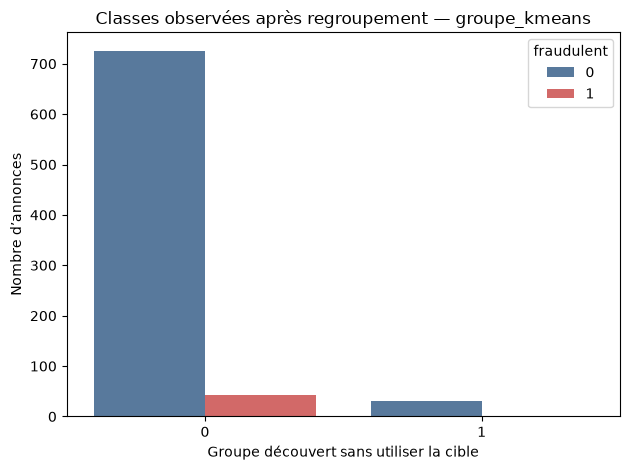

,annonces,taux_fraude
groupe_cah,,
0,769,0.055917
1,31,0.000000


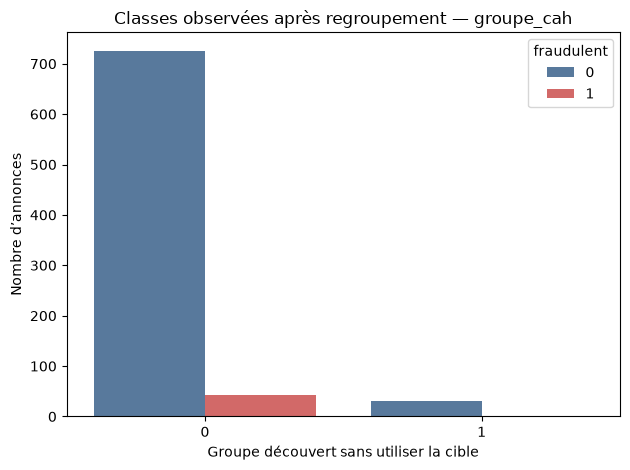

Lecture : les groupes peuvent contenir les deux classes. K-Means et CAH sont exploratoires et ne remplacent pas les classifieurs supervisés.


In [18]:
from sklearn.decomposition import TruncatedSVD
from sklearn.cluster import KMeans, AgglomerativeClustering

cluster_sample = train.sample(n=min(800, len(train)), random_state=SEED).copy()
cluster_text = cluster_sample[TEXT_FIELDS].fillna('').astype(str).agg(' '.join, axis=1)
cluster_tfidf = TfidfVectorizer(stop_words='english', max_features=10000, min_df=2)
cluster_matrix = cluster_tfidf.fit_transform(cluster_text)
cluster_dimensions = min(50, cluster_matrix.shape[1] - 1)
cluster_vectors = TruncatedSVD(n_components=cluster_dimensions, random_state=SEED).fit_transform(cluster_matrix)

cluster_sample['groupe_kmeans'] = KMeans(n_clusters=2, random_state=SEED, n_init=10).fit_predict(cluster_vectors)
cluster_sample['groupe_cah'] = AgglomerativeClustering(n_clusters=2).fit_predict(cluster_vectors)
for group_col in ['groupe_kmeans', 'groupe_cah']:
    summary = cluster_sample.groupby(group_col)[TARGET].agg(['count', 'mean']).rename(columns={'count': 'annonces', 'mean': 'taux_fraude'})
    display(summary)
    sns.countplot(data=cluster_sample, x=group_col, hue=TARGET, palette=['#4C78A8', '#E45756'])
    plt.title(f'Classes observées après regroupement — {group_col}')
    plt.xlabel('Groupe découvert sans utiliser la cible')
    plt.ylabel('Nombre d’annonces')
    plt.tight_layout()
    plt.show()
print('Lecture : les groupes peuvent contenir les deux classes. K-Means et CAH sont exploratoires et ne remplacent pas les classifieurs supervisés.')

## Conclusion et limites

Le projet compare une règle traditionnelle et quatre classifieurs supervisés, avec séparation stratifiée, validation à quatre plis, métriques adaptées au déséquilibre, matrices de confusion et graphique comparatif.

Limites : le CSV fourni contient 12 000 annonces, le fichier test n’a pas d’étiquettes, les règles lexicales sont simples et les fraudes évoluent. Une suite possible consiste à évaluer un corpus plus récent et à ajouter SHAP si la méthode d’explication est compatible avec le pipeline.